# Fake dataset generation and upper-limits
F. Acero, June 2026.
Simulation of fake datasets to probe the behavior of upper-limit computation gammapy v2.0.1.  
Script accompanying the gammapy v2 paper.

In this script we :  

- Build a fake `SpectrumDatasetOnOff` with CTAO IRFs and pure background for a given exposure time
- Use `FluxPointsEstimator` to derive upper-limits+sensitivity using the profile likelihood (frequentist approach)
- Use the `Sampler` class to perform a nested sampling analysis and derive upper-limits via the samples
  

In [360]:
%matplotlib inline

import numpy as np
import astropy.units as u
from astropy.coordinates import Angle, SkyCoord
from regions import CircleSkyRegion
from scipy.stats import norm
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from scipy import interpolate
from scipy.stats import median_abs_deviation as mad
from ipywidgets.widgets.interaction import interact
from astropy.visualization import quantity_support

plt.rcParams.update({'font.size': 12})
plt.rcParams.update({'font.family': 'serif'})

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 14

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=MEDIUM_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=MEDIUM_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

import gammapy
print(gammapy.__version__)

2.0.dev3770+g3c52c99d8


In [2]:
import os 
os.environ['GAMMAPY_DATA'] = '/Users/facero/Documents/Work/Program/gammapy-data/dev'

In [73]:
from gammapy.data import FixedPointingInfo, Observation, observatory_locations
from gammapy.datasets import Datasets, SpectrumDataset, SpectrumDatasetOnOff
from gammapy.estimators import FluxPointsEstimator, FluxPoints
from gammapy.estimators.flux import FluxEstimator
from gammapy.irf import load_irf_dict_from_file
from gammapy.makers import SpectrumDatasetMaker
from gammapy.maps import MapAxis, RegionGeom, LabelMapAxis, Map
from gammapy.modeling import Fit, Sampler, Parameter, stat_profile_ul_scipy
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel, LogUniformPrior, UniformPrior
from gammapy.utils.parallel import run_multiprocessing


In [2]:
def build_observation(livetime="1 h"):
    # Define simulation parameters parameters
    livetime = u.Quantity(livetime)

    pointing_position = SkyCoord(0, 0, unit="deg", frame="galactic")
    # We want to simulate an observation pointing at a fixed position in the sky.
    # For this, we use the `FixedPointingInfo` class
    pointing = FixedPointingInfo(
        fixed_icrs=pointing_position.icrs,
    )
    
    irfs = load_irf_dict_from_file(
        "$GAMMAPY_DATA/cta-caldb/Prod5-South-20deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz"
    )

    location = observatory_locations["ctao_south"]
    return Observation.create(
        pointing=pointing,
        livetime=livetime,
        irfs=irfs,
        location=location,
    )


def build_dataset(obs, offset="0.5 deg"):
    offset = u.Quantity(offset)

    # Reconstructed and true energy axis
    energy_axis = MapAxis.from_energy_bounds(0.05, 50, 6, per_decade=True, unit="TeV")
    energy_axis_true = MapAxis.from_energy_bounds(0.02, 100, 12, per_decade=True, unit="TeV", name="energy_true")

    on_region_radius = Angle("0.11 deg")

    pointing_position = obs.get_pointing_icrs(obs.tmid)
    center = pointing_position.directional_offset_by(
        position_angle=0 * u.deg, separation=offset
    )
    
    on_region = CircleSkyRegion(center=center, radius=on_region_radius)

    # Make the SpectrumDataset
    geom = RegionGeom.create(region=on_region, axes=[energy_axis])

    dataset_empty = SpectrumDataset.create(
        geom=geom, energy_axis_true=energy_axis_true, name="obs-0"
    )
    maker = SpectrumDatasetMaker(selection=["exposure", "edisp", "background"])

    return maker.run(dataset_empty, obs)


def fake_dataset_on_off(dataset, model, seed):
    dataset_on_off = SpectrumDatasetOnOff.from_spectrum_dataset(
        dataset=dataset, acceptance=1, acceptance_off=10
    )
    
    dataset_on_off.models = model.copy()
    dataset_on_off.fake(npred_background=dataset.npred_background(),random_state=seed)
    
    return dataset_on_off

def asimov_dataset(dataset,model):
    dataset.models = model.copy()    
    dataset.counts = dataset.npred()
    return dataset

def fake_dataset(dataset, model, seed):
    dataset.models = model.copy()
    dataset.fake(random_state=seed)
    return dataset

def build_model_pow(amplitude=1e-12):
    model_simu = PowerLawSpectralModel(index=2, amplitude=f'{amplitude} cm-2 s-1 TeV-1')
    return SkyModel(spectral_model=model_simu, name="source")


def build_simulation(exposure,E1,E2):
    obs = build_observation(livetime=exposure)
    dataset = build_dataset(obs)
    dataset.mask_fit = dataset.counts.geom.energy_mask(E1,E2)
    
     #no signal
    skymodel_simu=build_model_pow(amplitude = 1e-20) # almost no signal for simu
    skymodel_fit=build_model_pow(amplitude = 1e-13)  # reasonable starting point for fitting UL
    skymodel_fit.spectral_model.index.frozen = True
    skymodel_simu.spectral_model.index.frozen = True

    return dataset, skymodel_fit, skymodel_simu

In [328]:
def fake_analyze(dataset, simu_model, fit_model, fpe_config, seed, dataset_type='on'):
    results = {}

    print(fit_model)
    sampler_model = fit_model.copy()

#    min_amplitudes = [0]
    min_amplitudes = [0, -3e-14]
    max_amplitude  = 1e-11

    for min_amplitude, name in zip(min_amplitudes,["zero", "negative"]):
#    for min_amplitude, name in zip(min_amplitudes,["zero"]):
    
#        faked_dataset = fake_dataset_on_off(dataset, simu_model, seed)

        if dataset_type == 'onoff':
            faked_dataset = fake_dataset_on_off(dataset, simu_model, seed)
        elif dataset_type == 'on':
            faked_dataset = fake_dataset(dataset, simu_model, seed)
        elif dataset_type == 'asimov':
            faked_dataset = asimov_dataset(dataset, simu_model)
        else:
            print('Dataset type not supported. Choices are  on, onoff, asimov')
            
        faked_dataset.models =  fit_model #reset model to a reasonable model for fitting
    
        faked_dataset.models[0].spectral_model.amplitude.min=min_amplitude
        faked_dataset.models[0].spectral_model.amplitude.max=max_amplitude
        faked_dataset.models[0].spectral_model.amplitude.scan_min=min_amplitude
        faked_dataset.models[0].spectral_model.amplitude.scan_max=max_amplitude

        print(faked_dataset.models[0].spectral_model.amplitude)    

        if name == 'zero':
            norm=Parameter(name="norm",value=1,min=min_amplitude,scan_min=1e-6,scan_max=10,scan_n_values=50, interp="log")
        else:
            norm=Parameter(name="norm",value=1,min=-0.1,scan_min=-0.1,scan_max=5,scan_n_values=100, interp="linear")
            
        #estimator = FluxEstimator(**fpe_config)
        estimator = FluxPointsEstimator( # so taht we can have the amplitude param not the flux
            source="source",
            energy_edges=[E1,E2], **fpe_config  ,  norm=norm )
        

        res = estimator.run([faked_dataset])
        delta_ts=2.706
        refamp=(res.reference_spectral_model.amplitude.factor*res.reference_spectral_model.amplitude.scale)
        norm_scan = res.stat_scan.geom.axes['norm'].center * refamp

        try:
            ul_stat_scan = stat_profile_ul_scipy(res.stat_scan.geom.axes['norm'].center, res.stat_scan.data.flatten()-res.stat_scan.data.flatten().min(), delta_ts=delta_ts )
            ul_stat_scan*= refamp
        
        except:
            print('stat_profile_ul_scipy faild to find root')
            ul_stat_scan=np.nan
        
        f = interpolate.interp1d(norm_scan, res.stat_scan.data.flatten()-res.stat_scan.data.flatten().min(),fill_value='extrapolate')

#        print(type(norm_scan.min().value), norm_scan.max(),  norm.scan_n_values)
        if name == 'zero':
            norm_scan_new = np.logspace(np.log10(norm_scan.min().value), np.log10(norm_scan.max().value),norm.scan_n_values*50)
        else:
            norm_scan_new = np.linspace((norm_scan.min().value), (norm_scan.max().value),norm.scan_n_values*50)
            
        idx = np.argmin(np.abs(f(norm_scan_new) - delta_ts))

        plot=False
        if plot :
            plt.plot(norm_scan, res.stat_scan.data.flatten()-res.stat_scan.data.flatten().min())
            plt.plot(norm_scan, res.stat_scan.data.flatten()-res.stat_scan.data.flatten().min())
            
            plt.xscale('log')
            plt.axhline(y=2.706)
            plt.axvline(ul_stat_scan,label='gammapy scipy UL')
            plt.axvline(norm_scan_new[idx],ls='--',label='interp1D UL')
            plt.legend()
            plt.show()
        
        results[f'profile-{name}'] = res
        results[f'profile-scan-{name}'] = ul_stat_scan
        results[f'profile-scan-interp-{name}'] = norm_scan_new[idx]
        
        results['seed'] = seed

        dataset.write(f'toymodel-seed{seed}', overwrite=True)
        sampler_model.spectral_model.amplitude.prior = UniformPrior(min=min_amplitude, max=max_amplitude)
        faked_dataset.models = sampler_model
        
#        sampler_opts = {"live_points": 400, "frac_remain": 0.3,"log_dir": None, "show_status": False}
#        sampler = Sampler(backend="ultranest", sampler_opts=sampler_opts)
        sampler=Sampler(backend="ultranest", options={"min_num_live_points": 300, "log_dir": None, "viz_callback":False, "show_status": False})
    
        results[f'uniform-{name}'] = sampler.run([faked_dataset])

        
    return results

def extract_ul_from_samples(samples, confidence_level=0.954):
    return np.quantile(samples[:,0], confidence_level)

def perform_simulation(nsim, dataset, simu_model, fit_model, fpe_config, seed="random-seed",dataset_type='on'):
    indices = np.arange(nsim)

    # Force n_jobs to one to avoid multiprocessing in subprocess
    #fpe_config["n_jobs"] = 1
    
    if seed=="random-seed":
        inputs = [(dataset, simu_model, fit_model, fpe_config, "random-seed",dataset_type)  for seed in indices]
    if seed=="range":
        inputs = [(dataset, simu_model, fit_model, fpe_config, seed, dataset_type)  for seed in indices]
    
    fps = run_multiprocessing(fake_analyze, inputs, task_name="simulation")
#    fps = fake_analyze(dataset, simu_model, fit_model, fpe_config)
    
    return fps


# Testing for a simple one run call

In [274]:
#norm = Parameter(name="norm", value=1.0, interp="log")
#fpe_config = {"selection_optional":["all"], "n_sigma_ul":2, "n_sigma_sensitivity":2, "norm":norm}
fpe_config = {"selection_optional":["all"], "n_sigma_ul":1.645, "n_sigma_sensitivity":2}


# one run only
#results=fake_analyze(dataset, skymodel_simu, skymodel_fit, fpe_config)

#muliple runs 
Nrun=1
#seed="random-state" #random seed for each fake()
seed="range" #the seed in range(Nrun). the same everytime you run the script.
results = perform_simulation(Nrun, dataset, skymodel_simu, skymodel_fit, fpe_config, seed=seed, dataset_type='on')
results_asimov = perform_simulation(1, dataset, skymodel_simu, skymodel_fit, fpe_config, seed=seed,dataset_type='asimov')    


SkyModel

  Name                      : source
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                 (frozen):      2.000                   
    amplitude                     :   1.00e-13   +/- 0.0e+00 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         


Parameter(name='amplitude', value=1e-13, factor=np.float64(1e-13), scale=1.0, unit=Unit("1 / (TeV s cm2)"), min=0.0, max=1e-11, frozen=False, prior=None, id=0x131753e30)
1e-13
[ultranest] Sampling 300 live points from prior ...
[ultranest] Explored until L=4e+04  
[ultranest] Likelihood function evaluations: 2700
[ultranest]   logZ = 4.184e+04 +- 0.0947
[ultranest] Effective samples strategy satisfied (ESS = 705.2, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.06 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (

In [363]:
from matplotlib.ticker import MaxNLocator




def plot_lc_triangle(uls_profile_zero,  uls_uniform_zero, histbins = 25):
    
    fig, (ax, axh) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[3, 1], wspace=0.05),
                              sharey=True)   
    alpha=0.6
    
    Nrun=np.shape(uls_profile_zero)[0]
    x=np.arange(Nrun)
    failed=np.isnan(uls_profile_zero).sum()
    print(f'Nb of Nan in LL profile:{failed} ({failed/Nrun*100:.1f} %) ')
    with quantity_support():


        ax.scatter(x,uls_profile_zero, alpha=alpha,
                         marker='v',color='tab:orange', label="UL profile")
        
        ax.scatter(x,uls_uniform_zero, alpha=alpha,
                         marker='o',color='tab:blue', label="UL sampler")

            
        q11, q12=0.16, 0.84 # 1 sigma
        q21, q22=0.023, 0.977 #2sigma

        qmed = 0.5
        ax.axhline(y=np.nanquantile(uls_profile_zero,qmed), alpha=alpha,label=r"median", ls='--', color='tab:orange' )
        ax.axhline(y=np.nanquantile(uls_uniform_zero,qmed), alpha=alpha,label=r"median", ls='--', color='tab:blue' )
        
#        ax.axhline(y=np.nanquantile(uls_uniform_zero,q11), alpha=alpha,label=r"1$\sigma$ containment", ls='--', color='tab:blue' )
#        ax.axhline(y=np.nanquantile(uls_uniform_zero,q12), alpha=alpha, color='tab:blue',ls='--' )
#        ax.axhline(y=np.nanquantile(uls_profile_zero,q11), alpha=alpha,label=r"1$\sigma$ containment", ls=':', color='tab:orange' )
#        ax.axhline(y=np.nanquantile(uls_profile_zero,q12), alpha=alpha, color='tab:orange', ls=':' )

#        ax.axhline(y=np.nanquantile(uls_uniform_zero,q21), alpha=alpha,label=r"2$\sigma$ containment", ls='--', color='tab:blue' )
#        ax.axhline(y=np.nanquantile(uls_uniform_zero,q22), alpha=alpha, color='tab:blue',ls='--' )
#        ax.axhline(y=np.nanquantile(uls_profile_zero,q21), alpha=alpha,label=r"2$\sigma$ containment", ls=':', color='tab:orange' )
#        ax.axhline(y=np.nanquantile(uls_profile_zero,q22), alpha=alpha, color='tab:orange', ls=':' )    

#        ax.axhline(y=uls_profile_zero_asimov, alpha=alpha, color='tab:grey', ls='--',label='Asimov UL profile' )    
#        ax.axhline(y=uls_uniform_zero_asimov, alpha=alpha, color='tab:grey', ls=':',label='Asimov UL Sampler ' )    
        
    #ax.set_yscale('log')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=11))
    ax.set_xlabel('Realization')
    ax.set_ylabel(r'Differential Flux 95% UL [TeV$^{-1}$ cm$^{-2}$ s$^{-1}$]')
    ax.set_ylim(1e-16,4e-12)
    ax.set_yscale('log')
    ax.legend()

#    uls_profile_zero=uls_profile_zero.value #removing units
    # side histogram of the ULs
    #warning there could be some negative values in uls_profile_zero 
    bins = np.logspace(np.log10(np.nanmin(uls_profile_zero[uls_profile_zero>0])), np.log10(np.nanmax(uls_profile_zero)), histbins)

    axh.hist(uls_uniform_zero, bins=bins, orientation="horizontal", color='tab:blue', alpha=alpha)
#    axh.axhline(np.nanmedian(uls_uniform_zero), color='tab:blue', ls="--", lw=2,label='med(sampler)')
#    axh.axhline(uls_uniform_zero_asimov, color='tab:blue', ls=":", lw=1,label='med(sampler asimov)')
    
    axh.hist(uls_profile_zero, bins=bins, orientation="horizontal", color='tab:orange', alpha=alpha)
#    axh.axhline(np.nanmedian(uls_profile_zero), color='tab:orange', ls="--", lw=2,label='med(profile)')
#    axh.axhline(uls_profile_zero_asimov, color='tab:orange', ls=":", lw=1,label='med(profile asimov)')
    
    axh.set_xlabel("Occurence"); axh.tick_params(labelleft=False)

#    axh.legend()
    
    return ax   



## ---- Figure 2 - Dependence of bkg level ----
Running scripts for multiple background levels to see dependence on low/high statistics

ideally this loop should create a dict for easier handling in plotting function and saving to disk

In [329]:

E1,E2= 0.05*u.TeV, 50*u.TeV

fpe_config = {"selection_optional":["all"], "n_sigma_ul":1.645, "n_sigma_sensitivity":2}
confidence_level_samples=0.954
Nrun=100
#seed="random-state" #random seed for each fake()
seed="range" #the seed in range(Nrun). the same everytime you run the script.
ref_amplitude = skymodel_fit.spectral_model.amplitude.quantity

exposures=["0.03 h", "0.3 h","100 h"]

uls_profile_zero_list = []
uls_profile_scan_zero_list = []
uls_profile_scan_interp_zero_list = []

sensitivity_zero_list = []
uls_uniform_zero_list = []

uls_uniform_negative_list = []
uls_profile_negative_list =[]
uls_profile_scan_negative_list=[]
uls_profile_scan_interp_negative_list=[]

uls_uniform_zero_asimov_list=[]
uls_profile_scan_zero_asimov_list=[]
uls_uniform_negative_asimov_list = []
uls_profile_scan_negative_asimov_list = []

bkg_counts_list=[]


dry_run=False
for exposure in exposures:

    dataset, skymodel_fit, skymodel_simu = build_simulation(exposure,E1,E2)
    bkg_counts=dataset.npred_background().data[dataset.mask].sum()
    print(f"Expected background in ON region: {bkg_counts:.2f}")
    bkg_counts_list.append(bkg_counts)
    
    if dry_run==False:

        
        results = perform_simulation(Nrun, dataset, skymodel_simu, skymodel_fit, fpe_config, seed=seed,dataset_type='on')    
        results_asimov = perform_simulation(1, dataset, skymodel_simu, skymodel_fit, fpe_config, seed=seed,dataset_type='asimov')    

        sensitivity_zero_list.append( np.array([res['profile-zero']['norm_sensitivity'].data.flatten()[0] for res in results])*ref_amplitude)

        uls_profile_zero_list.append( np.array([res['profile-zero']['norm_ul'].data.flatten()[0] for res in results])*ref_amplitude)
        uls_profile_scan_zero_list.append( np.array([res['profile-scan-zero'] for res in results]))
        uls_profile_scan_interp_zero_list.append( np.array([res['profile-scan-interp-zero'] for res in results]))
        uls_uniform_zero_list.append( np.array([extract_ul_from_samples(res["uniform-zero"].samples,confidence_level=confidence_level_samples) for res in results]))

        uls_profile_negative_list.append( np.array([res['profile-negative']['norm_ul'].data.flatten()[0] for res in results])*ref_amplitude)
        uls_profile_scan_negative_list.append( np.array([res['profile-scan-negative'] for res in results]))
        uls_profile_scan_interp_negative_list.append( np.array([res['profile-scan-interp-negative'] for res in results]))
        uls_uniform_negative_list.append( np.array([extract_ul_from_samples(res["uniform-negative"].samples,confidence_level=confidence_level_samples) for res in results]))

        
        #Asmimov
        uls_uniform_zero_asimov_list.append( np.array([extract_ul_from_samples(res["uniform-zero"].samples,confidence_level=confidence_level_samples) for res in results_asimov]))
        uls_profile_scan_zero_asimov_list.append( np.array([res['profile-scan-zero'] for res in results_asimov]))

        uls_uniform_negative_asimov_list.append( np.array([extract_ul_from_samples(res["uniform-negative"].samples,confidence_level=confidence_level_samples) for res in results_asimov]))
        uls_profile_scan_negative_asimov_list.append( np.array([res['profile-scan-negative'] for res in results_asimov]))

#        uls_uniform_negative_list.append( np.array([extract_ul_from_samples(res["uniform-negative"].samples) for res in results]) )
#        uls_profile_negative_list.append( np.array([res['profile-negative']['norm_ul'].data.flatten()[0] for res in results])*ref_amplitude )

    

Expected background in ON region: 10.04
SkyModel

  Name                      : source
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                 (frozen):      2.000                   
    amplitude                     :   1.00e-13   +/- 0.0e+00 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         


Parameter(name='amplitude', value=1e-13, factor=np.float64(1e-13), scale=1.0, unit=Unit("1 / (TeV s cm2)"), min=0.0, max=1e-11, frozen=False, prior=None, id=0x321a63b60)
stat_profile_ul_scipy faild to find root
[ultranest] Sampling 300 live points from prior ...
[ultranest] Explored until L=2  
[ultranest] Likelihood function evaluations: 1112
[ultranest]   logZ = -0.4416 +- 0.04963
[ultranest] Effective samples strategy satisfied (ESS = 646.8, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.47+-0.08 nat, ne

Value -0.10000000000000009 is outside bounds [-0.1, nan] for parameter 'norm'
Value -0.10000000000000009 is outside bounds [-0.1, nan] for parameter 'norm'



logZ = 157.095 +- 0.461
  single instance: logZ = 157.095 +- 0.118
  bootstrapped   : logZ = 157.096 +- 0.220
  tail           : logZ = +- 0.405
insert order U test : converged: True correlation: inf iterations

    amplitude           : 0.000000000000000│▆▇▆▅▄▃▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁▁ ▁   ▁ │0.000000000000396    0.000000000000053 +- 0.000000000000051

Parameter(name='amplitude', value=1e-13, factor=np.float64(1e-13), scale=1.0, unit=Unit("1 / (TeV s cm2)"), min=-3e-14, max=1e-11, frozen=False, prior=None, id=0x1322b03e0)
[ultranest] Sampling 300 live points from prior ...
[ultranest] Explored until L=2e+02  
[ultranest] Likelihood function evaluations: 2029
[ultranest]   logZ = 157.4 +- 0.1108
[ultranest] Effective samples strategy satisfied (ESS = 720.9, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.10 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.42, need <0.5)
[ultranest]   logZ error budget: single: 0.12 b

# Save to disk via a dict, currently not working needs to be fixed.

ideally the dict should be created before in the loop and below just dumping to disk

In [250]:
uls_dict={}

suffixes = [
    "zero_list",
    "negative_list",
    "zero_asimov_list",
    "negative_asimov_list"
]

for suffix in suffixes:
    var_name = f"uls_profile_scan_{suffix}"
    # Fetch the variable dynamically using globals()
    uls_dict[suffix] = globals()[var_name]


uls_dict['uls_profile_zero'] = uls_profile_zero_list
uls_dict['uls_profile-scan-zero'] = uls_profile_scan_zero_list
uls_dict['uls_profile-scan-interp-zero'] = uls_profile_scan_interp_zero_list

uls_dict['uls_uniform_zero'] = uls_uniform_zero_list
uls_dict['sensitivity_zero'] = sensitivity_zero_list

uls_dict['uls_profile-scan-zero-asimov'] = uls_profile_scan_zero_asimov_list
uls_dict['uls_uniform_zero-asimov'] = uls_uniform_zero_asimov_list



uls_dict['exposures']=exposures
uls_dict['confidence_level_samples']= confidence_level_samples
uls_dict['fpe_config']=fpe_config
uls_dict['bkg_counts_list'] = bkg_counts_list

import pickle
outfile=f'uls_results_Nrun_{Nrun}_constrain-zero_stat_scan.pkl'
#with open(outfile, 'wb') as fp:
#    pickle.dump(uls_dict, fp)
print(f'Written results to {outfile}')


Written results to uls_results_Nrun_23_constrain-zero_stat_scan.pkl


# Loading from disk when needed, needs to be fixed.

In [45]:
infile='uls_results_Nrun_100_constrain-zero.pkl'

with open(infile, 'rb') as fp:
    uls_dict=pickle.load(fp)
print(f'Loaded results from {infile}')


Loaded results from uls_results_Nrun_100_constrain-zero.pkl


0.03 h
10.044623073669332
Nb of Nan in LL profile:28 (28.0 %) 
Bayes/profile Asimov = 1.59
MAD(UL_prof)/median(UL_prof) = 0.18
MAD(UL_sampler)/median(UL_sampler) = 0.19


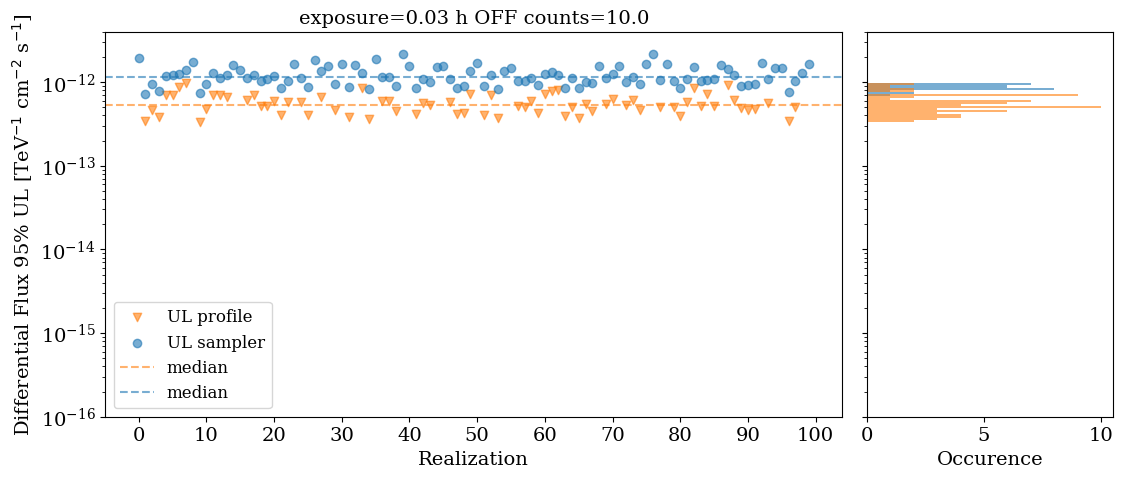

0.3 h
100.44623073669555
Nb of Nan in LL profile:0 (0.0 %) 
Bayes/profile Asimov = 1.50
MAD(UL_prof)/median(UL_prof) = 0.36
MAD(UL_sampler)/median(UL_sampler) = 0.19


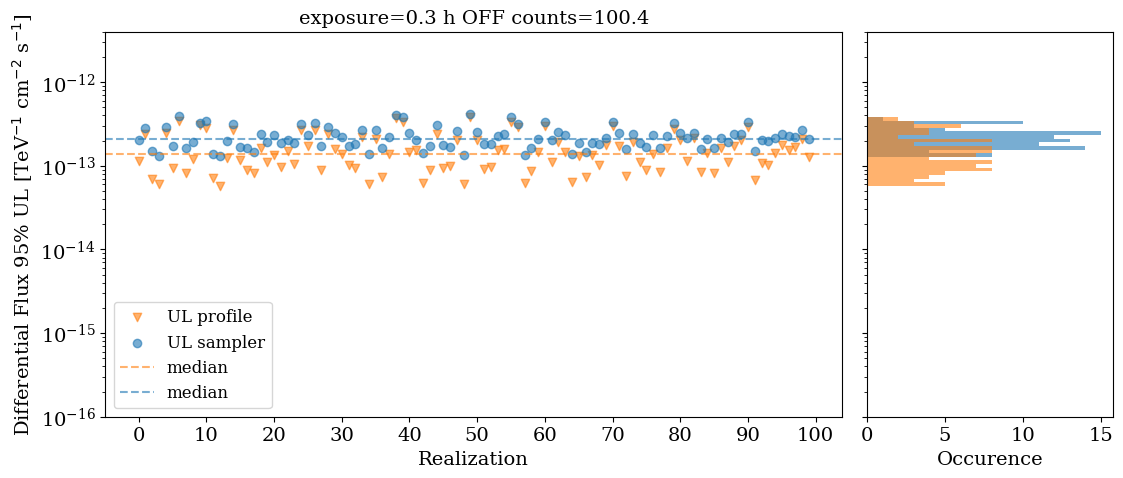

100 h
33482.076912231816
Nb of Nan in LL profile:0 (0.0 %) 
Bayes/profile Asimov = 1.23
MAD(UL_prof)/median(UL_prof) = 0.37
MAD(UL_sampler)/median(UL_sampler) = 0.21


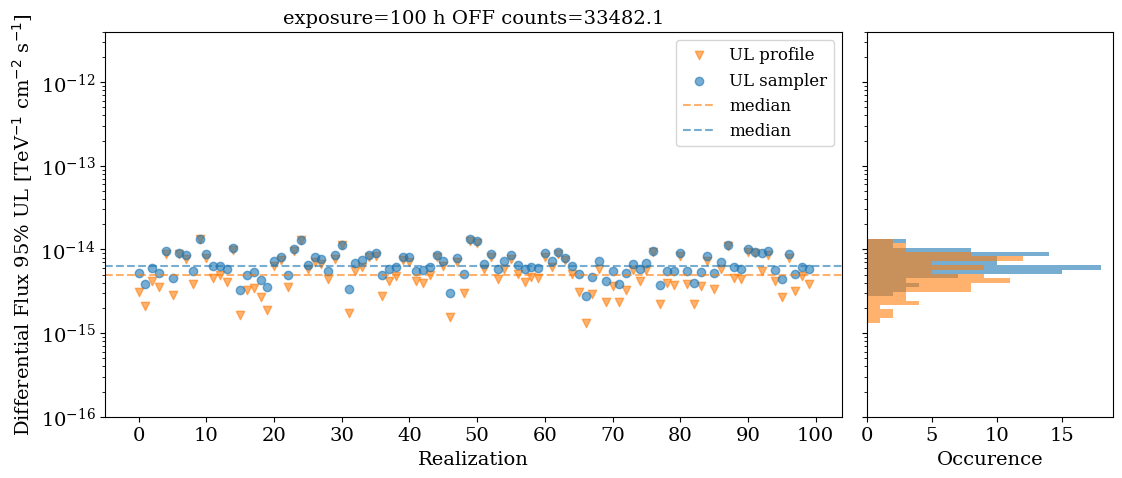

In [365]:
prior='zero'

#for i,exposure in enumerate(["0.3 h","1 h", "3 h"]):
for i,exposure in enumerate(exposures):
    
    print(exposure)
    print(bkg_counts_list[i])
#    plot_lc(uls_uniform_zero_list[i], uls_profile_zero_list[i],sensitivity_zero_list[i])
#    ax=plot_lc_triangle2( uls_uniform_zero_list[i], uls_profile_zero_list[i],histbins=20)
    ax=plot_lc_triangle(  uls_profile_scan_zero_list[i],
                          uls_uniform_zero_list[i],histbins=20)
    
    print(f'Bayes/profile Asimov = { uls_uniform_zero_asimov_list[i][0]/uls_profile_scan_zero_asimov_list[i][0]:.2f}')
    m=np.isnan(uls_profile_scan_zero_list[i])
    print(f'MAD(UL_prof)/median(UL_prof) = { (mad(uls_profile_scan_zero_list[i][~m])/np.median(uls_profile_scan_zero_list[i][~m]) ):.2f}')
    print(f'MAD(UL_sampler)/median(UL_sampler) = { (mad(uls_uniform_zero_list[i])/np.median(uls_uniform_zero_list[i]) ):.2f}')
    
    ax.set_title(f'exposure={exposure} OFF counts={bkg_counts_list[i]:.1f}')
    plt.savefig(f'UL_comparison_exp_{exposure}_prior_{prior}.pdf')
    plt.show()
#    print(uls_profile_zero_list[i])
#    print(uls_uniform_zero_list[i])
    

# Unconstrained prior (norm can go negative)

Negative allowed
0.03 h
10.044623073669332
Nb of Nan in LL profile:71 (71.0 %) 
Bayes/profile Asimov = nan
MAD(UL_prof)/median(UL_prof) = 0.11
MAD(UL_sampler)/median(UL_sampler) = 0.16


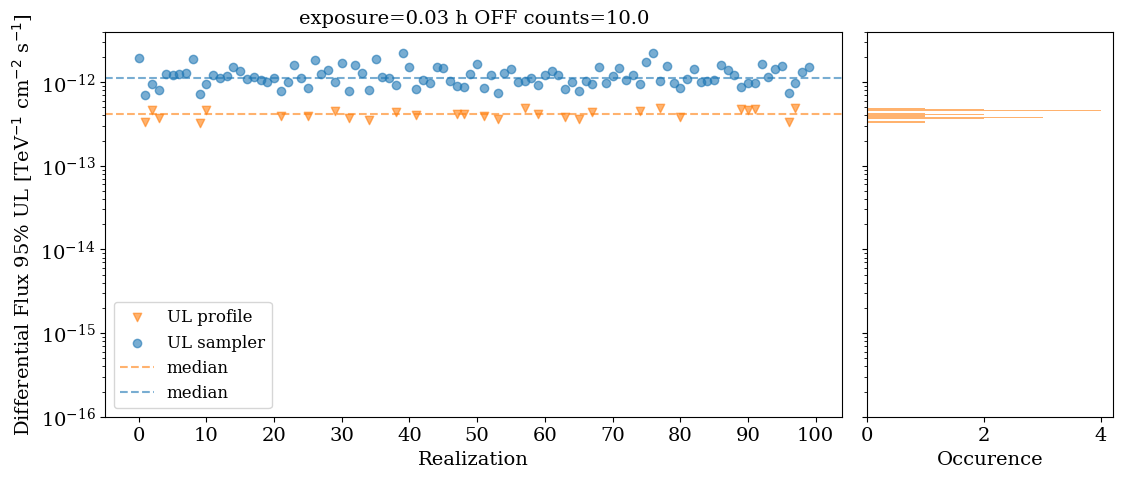

Negative allowed
0.3 h
100.44623073669555
Nb of Nan in LL profile:0 (0.0 %) 
Bayes/profile Asimov = 1.35
MAD(UL_prof)/median(UL_prof) = 0.40
MAD(UL_sampler)/median(UL_sampler) = 0.22


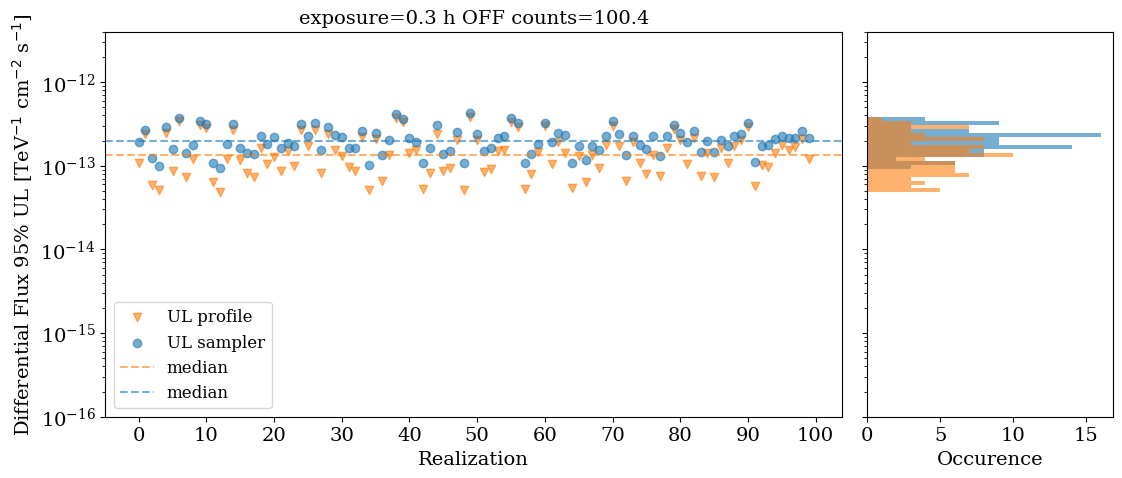

Negative allowed
100 h
33482.076912231816
Nb of Nan in LL profile:0 (0.0 %) 
Bayes/profile Asimov = 1.11
MAD(UL_prof)/median(UL_prof) = 0.46
MAD(UL_sampler)/median(UL_sampler) = 0.42


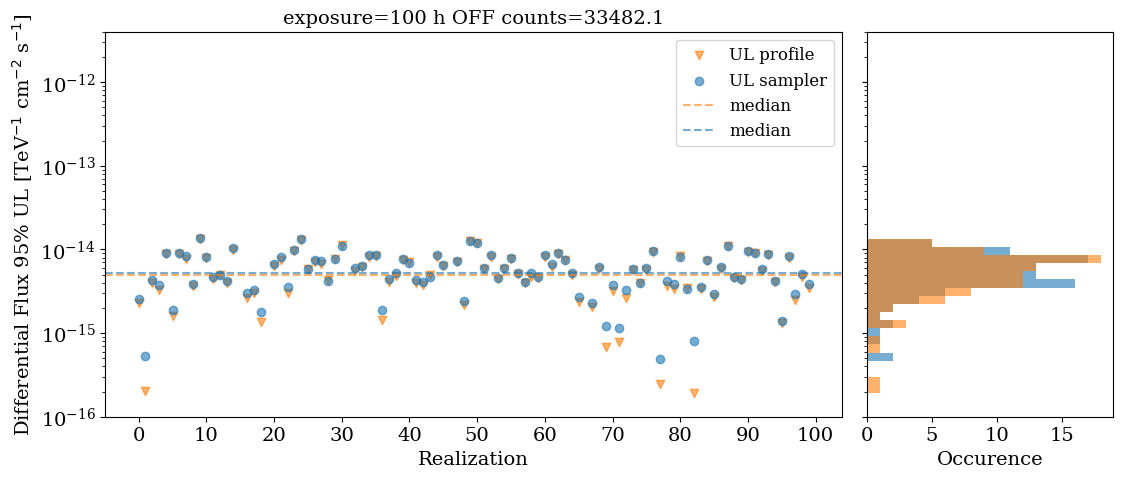

In [367]:
prior='negative'
#for i,exposure in enumerate(["0.3 h","1 h", "3 h"]):
for i,exposure in enumerate(exposures):

    print('Negative allowed')
    print(exposure)
    print(bkg_counts_list[i])
#    plot_lc(uls_uniform_zero_list[i], uls_profile_zero_list[i],sensitivity_zero_list[i])
#    ax=plot_lc_triangle2( uls_uniform_zero_list[i], uls_profile_zero_list[i],histbins=20)
    ax=plot_lc_triangle(  uls_profile_scan_negative_list[i],
                          uls_uniform_negative_list[i],histbins=20)
    
    print(f'Bayes/profile Asimov = { uls_uniform_negative_asimov_list[i][0]/uls_profile_scan_negative_asimov_list[i][0]:.2f}')
    m=np.isnan(uls_profile_scan_negative_list[i])
    print(f'MAD(UL_prof)/median(UL_prof) = { (mad(uls_profile_scan_negative_list[i][~m])/np.median(uls_profile_scan_negative_list[i][~m]) ):.2f}')
    print(f'MAD(UL_sampler)/median(UL_sampler) = { (mad(uls_uniform_negative_list[i])/np.median(uls_uniform_negative_list[i]) ):.2f}')
    
    ax.set_title(f'exposure={exposure} OFF counts={bkg_counts_list[i]:.1f}')
    plt.savefig(f'UL_comparison_exp_{exposure}_prior_{prior}.pdf')
    
    plt.show()
#    print(uls_profile_zero_list[i])
#    print(uls_uniform_zero_list[i])
    

# TEST ZONE STOP HERE. Don't go below

In [344]:
for i,exposure in enumerate(exposures):
    print(exposure)
    print(f'Profile constraint/profile unconstraint Asimov = { uls_profile_scan_zero_asimov_list[i][0]/uls_profile_scan_negative_asimov_list[i][0]:.2f}')
    print(f'Bayes constraint/Bayes unconstraint Asimov = { uls_uniform_zero_asimov_list[i][0]/uls_uniform_negative_asimov_list[i][0]:.2f}')
    print('--')
    print(f'median(UL_prof constr)/median(UL_prof unconstr) = {  np.nanmedian(uls_profile_scan_zero_list[i])/np.nanmedian(uls_profile_scan_negative_list[i]) :.2f}')
    print(f'median(UL_sampler constr)/median(UL_smapler unconstr) = { np.nanmedian(uls_uniform_zero_list[i])/np.median(uls_uniform_negative_list[i]):.2f}')    
    print('')


0.03 h
Profile constraint/profile unconstraint Asimov = nan
Bayes constraint/Bayes unconstraint Asimov = 1.00
--
median(UL_prof constr)/median(UL_prof unconstr) = 1.28
median(UL_sampler constr)/median(UL_smapler unconstr) = 1.00

0.3 h
Profile constraint/profile unconstraint Asimov = 1.00
Bayes constraint/Bayes unconstraint Asimov = 1.11
--
median(UL_prof constr)/median(UL_prof unconstr) = 1.03
median(UL_sampler constr)/median(UL_smapler unconstr) = 1.06

100 h
Profile constraint/profile unconstraint Asimov = 1.00
Bayes constraint/Bayes unconstraint Asimov = 1.11
--
median(UL_prof constr)/median(UL_prof unconstr) = 1.00
median(UL_sampler constr)/median(UL_smapler unconstr) = 1.20

